# Credit card fraud detection implementation

## Importing pandas and numpy

In [1]:
# Importing pandas
import pandas as pd

# Importing numpy
import numpy as np

## Loading the dataset

In [2]:
df = pd.read_csv('creditcard.csv')

## Understanding the dataset

### Checking the first few rows of the dataset

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Checking the total number of rows and columns of the dataset

In [4]:
df.shape

(284807, 31)

### Inspecting the properties of the dataset

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

### Checking the distribution in the `class` column

In [6]:
df.Class.value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

### Checking the percentage distribution of each class category

In [7]:
df.Class.value_counts(normalize=True) * 100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

### Checking for missing values

In [8]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

### Checking for duplicate records

In [9]:
df.duplicated().sum()

np.int64(1081)

### Checking for fraudulent transactions (Class 1) in the duplicted records

In [10]:
df[df.duplicated()].Class.value_counts()

Class
0    1062
1      19
Name: count, dtype: int64

## Cleaning the dataset

### Removing duplicate records

In [11]:
df.drop_duplicates(inplace=True)

### Checking dataset dimensions after duplicate removal

In [12]:
df.shape

(283726, 31)

### Checking for remaining duplicate records

In [13]:
df.duplicated().sum()

np.int64(0)

### Verifying the updated class distribution after duplicate removal

In [14]:
df.Class.value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

## Performing Exploratory data analysis

### Inspecting the summary statistics of the dataset

In [15]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,...,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,...,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687,0.001667
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,...,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437,0.040796
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,...,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000,0.000000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,...,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000,0.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,...,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,...,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000,1.000000


### Visualizing the distribution of transaction amounts

In [16]:
# Importing matplotlib
import matplotlib.pyplot as plt

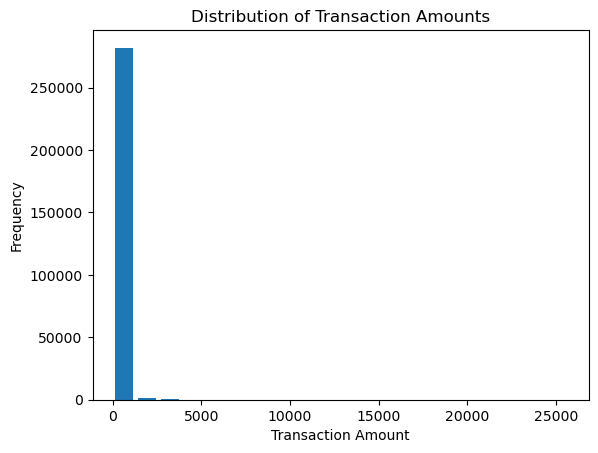

In [17]:
# Plotting a histogram
plt.hist(df.Amount, bins=20, rwidth=0.8)
plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')
plt.show()

### Creating two separate dataframes based on the `Class` categories

In [18]:
# DataFrame based on legitimate transactions (Class 0)
legitimate_transactions = df[df.Class == 0]
legitimate_transactions

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [19]:
# DataFrame based on fraudulent transactions (Class 1)
fraudulent_transactions = df[df.Class == 1]
fraudulent_transactions

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
541,406.0,-2.312227,1.951992,-1.609851,3.997906,-0.522188,-1.426545,-2.537387,1.391657,-2.770089,...,0.517232,-0.035049,-0.465211,0.320198,0.044519,0.177840,0.261145,-0.143276,0.00,1
623,472.0,-3.043541,-3.157307,1.088463,2.288644,1.359805,-1.064823,0.325574,-0.067794,-0.270953,...,0.661696,0.435477,1.375966,-0.293803,0.279798,-0.145362,-0.252773,0.035764,529.00,1
4920,4462.0,-2.303350,1.759247,-0.359745,2.330243,-0.821628,-0.075788,0.562320,-0.399147,-0.238253,...,-0.294166,-0.932391,0.172726,-0.087330,-0.156114,-0.542628,0.039566,-0.153029,239.93,1
6108,6986.0,-4.397974,1.358367,-2.592844,2.679787,-1.128131,-1.706536,-3.496197,-0.248778,-0.247768,...,0.573574,0.176968,-0.436207,-0.053502,0.252405,-0.657488,-0.827136,0.849573,59.00,1
6329,7519.0,1.234235,3.019740,-4.304597,4.732795,3.624201,-1.357746,1.713445,-0.496358,-1.282858,...,-0.379068,-0.704181,-0.656805,-1.632653,1.488901,0.566797,-0.010016,0.146793,1.00,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
279863,169142.0,-1.927883,1.125653,-4.518331,1.749293,-1.566487,-2.010494,-0.882850,0.697211,-2.064945,...,0.778584,-0.319189,0.639419,-0.294885,0.537503,0.788395,0.292680,0.147968,390.00,1
280143,169347.0,1.378559,1.289381,-5.004247,1.411850,0.442581,-1.326536,-1.413170,0.248525,-1.127396,...,0.370612,0.028234,-0.145640,-0.081049,0.521875,0.739467,0.389152,0.186637,0.76,1
280149,169351.0,-0.676143,1.126366,-2.213700,0.468308,-1.120541,-0.003346,-2.234739,1.210158,-0.652250,...,0.751826,0.834108,0.190944,0.032070,-0.739695,0.471111,0.385107,0.194361,77.89,1
281144,169966.0,-3.113832,0.585864,-5.399730,1.817092,-0.840618,-2.943548,-2.208002,1.058733,-1.632333,...,0.583276,-0.269209,-0.456108,-0.183659,-0.328168,0.606116,0.884876,-0.253700,245.00,1


### Comparing the summary statistics of the transaction amounts for both dataframes

In [20]:
# Checking the summary statistics of transaction amounts for legitimate transactions
legitimate_transactions.Amount.describe()

count    283253.000000
mean         88.413575
std         250.379023
min           0.000000
25%           5.670000
50%          22.000000
75%          77.460000
max       25691.160000
Name: Amount, dtype: float64

In [21]:
# Checking the summary statistics of transaction amounts for fraudulent transactions
fraudulent_transactions.Amount.describe()

count     473.000000
mean      123.871860
std       260.211041
min         0.000000
25%         1.000000
50%         9.820000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

### Visualizing the relationship between transaction amounts and legitimate/fraudulent transactions

In [22]:
# Importing seaborn
import seaborn as sns

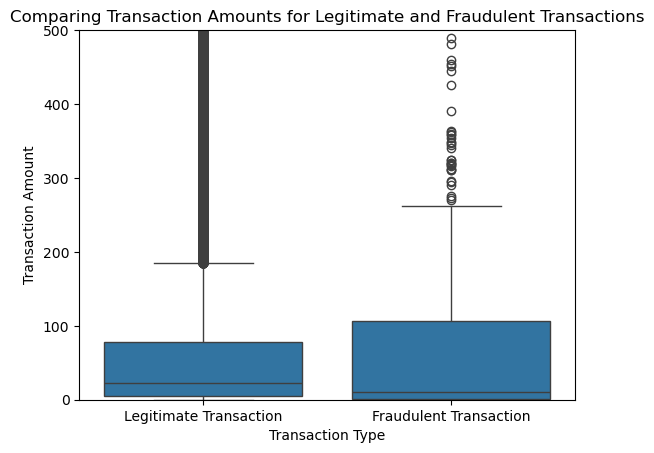

In [23]:
# Plotting a boxplot
sns.boxplot(x=df.Class.map({0:'Legitimate Transaction', 1:'Fraudulent Transaction'}), y=df.Amount)
plt.title('Comparing Transaction Amounts for Legitimate and Fraudulent Transactions')
plt.xlabel('Transaction Type')
plt.ylabel('Transaction Amount')
plt.ylim(0, 500)
plt.show()

## Preprocessing the data

### Separating the independent features (X) from the target variable (y)

In [24]:
# Creating the independent features (X)
X = df.drop('Class', axis='columns')

In [25]:
# Creating the target variable (y)
y = df.Class

### Splitting the dataset into training set and testing set

In [26]:
# Importing train_test_split
from sklearn.model_selection import train_test_split

In [27]:
# Splitting the dataset into training set and testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### Checking the dimensions of each split

In [28]:
print(f'X_train: {X_train.shape}, X_test: {X_test.shape}, y_train: {y_train.shape}, y_test: {y_test.shape}')

X_train: (226980, 30), X_test: (56746, 30), y_train: (226980,), y_test: (56746,)


### Checking the distribution of Class in the target variable

In [29]:
print(f'y_train: {y_train.value_counts()} \n{"=" * 30}\ny_test: {y_test.value_counts()}')

y_train: Class
0    226602
1       378
Name: count, dtype: int64 
y_test: Class
0    56651
1       95
Name: count, dtype: int64


### Scaling the features

In [30]:
# Importing StandardScaler
from sklearn.preprocessing import StandardScaler

In [31]:
# Creating an instance of StandardScaler
scaler = StandardScaler()

In [32]:
# Fitting and transforming the training features
X_train_scaled = scaler.fit_transform(X_train)

In [33]:
# Transforming the test features using the trained scaler
X_test_scaled = scaler.transform(X_test)

In [34]:
# Checking the dimensions of the scaled features
print(f'X_train_scaled: {X_train_scaled.shape}, X_test_scaled: {X_test_scaled.shape}')

X_train_scaled: (226980, 30), X_test_scaled: (56746, 30)


## Building a model

### Training the Logistic Regression model

In [35]:
# Importing LogisticRegression
from sklearn.linear_model import LogisticRegression

In [36]:
# Creating an instance of LogisticRegression
lr = LogisticRegression(
    class_weight = 'balanced',
    max_iter = 1000,
    random_state = 42
)

In [37]:
# Training the Logistic Regression model
lr.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


### Testing the Logistic Regression model

In [38]:
# Predicting the transaction classes
y_pred_lr = lr.predict(X_test_scaled)

In [39]:
# Displaying the first 10 predictions
y_pred_lr[:40]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

### Evaluating the Logistic Regression model performance

In [40]:
# Importing confusion_matrix
from sklearn.metrics import confusion_matrix

In [41]:
# Generating the confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_lr

array([[55262,  1389],
       [   12,    83]])

In [42]:
# Importing classification_report
from sklearn.metrics import classification_report

In [43]:
# Generating the classification report
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



### Visualizing the Logistic Regression Confusion Matrix

In [44]:
# Importing ConfusionMatrixDisplay
from sklearn.metrics import ConfusionMatrixDisplay

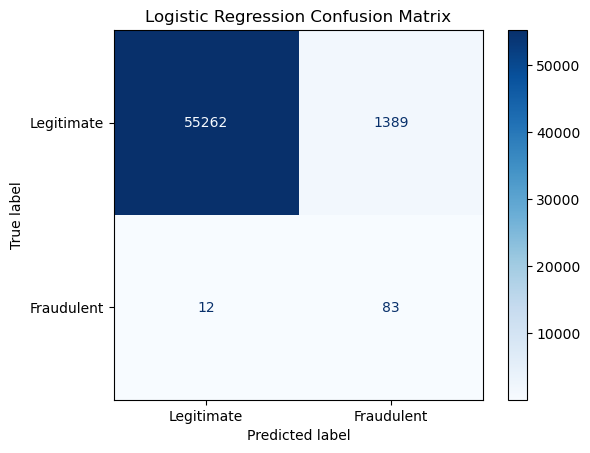

In [45]:
# Creating the visualization
cmd_lr = ConfusionMatrixDisplay(
    confusion_matrix = cm_lr,
    display_labels = ['Legitimate', 'Fraudulent']
)

cmd_lr.plot(cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.show()

## Building a second algorithm for comparison

### Training the Random Forest model

In [46]:
# Importing RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier

In [47]:
# Creating an instance of RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators = 100,
    class_weight = 'balanced',
    random_state = 42,
    n_jobs = -1
)

In [48]:
# Training the model
rf.fit(X_train_scaled, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### Testing the Random Forest model

In [49]:
# Predicting transaction classes on the test dataset
y_pred_rf = rf.predict(X_test_scaled)

In [50]:
# Displaying the first 10 predictions
y_pred_rf[:40]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

### Evaluating the Random Forest model performance

In [51]:
# Generating the confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_rf

array([[56649,     2],
       [   28,    67]])

In [52]:
# Generating the Random Forest classification report
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.71      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.85      0.91     56746
weighted avg       1.00      1.00      1.00     56746



### Visualizing the Random Forest Confusion Matrix

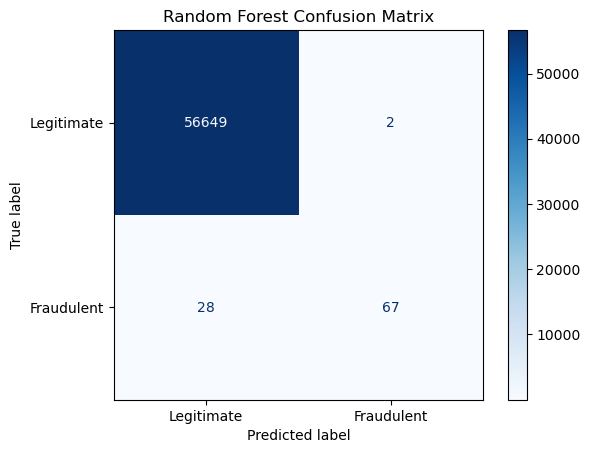

In [53]:
cmd_rf = ConfusionMatrixDisplay(
    confusion_matrix = cm_rf,
    display_labels = ['Legitimate', 'Fraudulent']
)

cmd_rf.plot(cmap='Blues')
plt.title('Random Forest Confusion Matrix')
plt.show()

## Creating a model performance comparison table

### Importing the evaluation metrics

In [54]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

### Creating the comparison table

In [55]:
model_comparison = pd.DataFrame({
    'Model' : ['Logistic Regression', 'Random Forest'],
    'Accuracy' : [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision' : [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],
    'Recall' : [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],
    'F1-score' : [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ]
})

### Displaying the comparison table

In [56]:
model_comparison

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.975311,0.056386,0.873684,0.105935
1,Random Forest,0.999471,0.971014,0.705263,0.817073


## Creating a validation set for probability threshold optimization 

### Splitting the training data into training and validation sets

In [57]:
X_train_new, X_val, y_train_new, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

### Verifying the dimensions of the training and validation features

In [58]:
print(f'Training set: {X_train_new.shape}, Validation set: {X_val.shape}')

Training set: (181584, 30), Validation set: (45396, 30)


### Scaling the training and validation features

In [59]:
# Creating a new scaler
scaler_val = StandardScaler()

In [60]:
# Fitting and transforming the training features
X_train_new_scaled = scaler_val.fit_transform(X_train_new)

In [61]:
# Transforming the validation features
X_val_scaled = scaler_val.transform(X_val)

### Verifying the dimensions of both scaled datasets

In [62]:
print(f'Scaled training set: {X_train_new_scaled.shape}, Scaled validation set: {X_val_scaled.shape}')

Scaled training set: (181584, 30), Scaled validation set: (45396, 30)


### Retraining Random Forest for threshold optimization

In [63]:
# Creating a new Random Forest instance
rf_val = RandomForestClassifier(
    n_estimators = 100,
    class_weight = 'balanced',
    random_state = 42,
    n_jobs = -1
)

In [64]:
# Training the model
rf_val.fit(X_train_new_scaled, y_train_new)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### Predicting fraud probabilities on the validation set

In [65]:
# Generating the fraud probabilities
y_val_proba = rf_val.predict_proba(X_val_scaled)[:, 1]

In [66]:
# Displaying the first 40 probabilities
y_val_proba[:40]

array([0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.06, 0.  , 0.  ,
       0.01, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ])

### Evaluating different probability thresholds

In [67]:
# Defining classification thresholds
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

In [68]:
# Evaluating each threshold
for threshold in thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    print(f'Threshold: {threshold}')
    print(f'Precision: {precision_score(y_val, y_val_pred):.4f}')
    print(f'Recall: {recall_score(y_val, y_val_pred):.4f}')
    print(f'F1-score: {f1_score(y_val, y_val_pred):.4f}')
    print('-' * 30)

Threshold: 0.5
Precision: 0.9677
Recall: 0.7895
F1-score: 0.8696
------------------------------
Threshold: 0.4
Precision: 0.9697
Recall: 0.8421
F1-score: 0.9014
------------------------------
Threshold: 0.3
Precision: 0.9420
Recall: 0.8553
F1-score: 0.8966
------------------------------
Threshold: 0.2
Precision: 0.9420
Recall: 0.8553
F1-score: 0.8966
------------------------------
Threshold: 0.1
Precision: 0.8462
Recall: 0.8684
F1-score: 0.8571
------------------------------


### Evaluating the Random Forest model using the selected threshold

In [69]:
# Scaling the original test features
X_test_val_scaled = scaler_val.transform(X_test)

In [70]:
# Predicting fraud probabilities
y_test_proba = rf_val.predict_proba(X_test_val_scaled)[:, 1]

In [71]:
# Applying the selected threshold
y_pred_optimized = (y_test_proba >= 0.4).astype(int)

### Generating the optimized Random Forest confusion matrix

In [72]:
cm_optimized = confusion_matrix(y_test, y_pred_optimized)
cm_optimized

array([[56648,     3],
       [   27,    68]])

### Generating the optimized Random Forest classification report

In [73]:
print(classification_report(y_test, y_pred_optimized))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.96      0.72      0.82        95

    accuracy                           1.00     56746
   macro avg       0.98      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746



## Predicting fraud probabilities using the original Random Forest model

### Generating fraud probabilities on the test set

In [74]:
y_test_proba_rf = rf.predict_proba(X_test_scaled)[:, 1]

### Applying the optimized probability threshold

In [75]:
y_pred_rf_optimized = (y_test_proba_rf >= 0.4).astype(int)

### Evaluating the original Random Forest model with the optimized threshold

In [76]:
# Generating the confusion matrix
cm_rf_optimized = confusion_matrix(y_test, y_pred_rf_optimized)
cm_rf_optimized

array([[56648,     3],
       [   26,    69]])

In [77]:
# Generating the classification report
print(classification_report(y_test, y_pred_rf_optimized))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.96      0.73      0.83        95

    accuracy                           1.00     56746
   macro avg       0.98      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746



## Comparing the performance of all three model configurations

### Creating the final model comparison table

In [78]:
final_comparison = pd.DataFrame({
    'Model' : [
        'Logistic Regression',
        'Random Forest (0.5)',
        'Random Forest (0.4)'
    ],
    'Accuracy' : [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_optimized)
    ],
    'Precision' : [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf_optimized)
    ],
    'Recall' : [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf_optimized)
    ],
    'F1-score' : [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf_optimized)
    ]
})

### Displaying the final model performance comparison

In [79]:
# Displaying the results rounded to four decimal places
final_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9753,0.0564,0.8737,0.1059
1,Random Forest (0.5),0.9995,0.9710,0.7053,0.8171
2,Random Forest (0.4),0.9995,0.9583,0.7263,0.8263


## Visualizing the final model performance comparison

### Selecting the evaluation metrics

In [80]:
metrics = final_comparison.set_index('Model')[
    ['Precision', 'Recall', 'F1-score']
]

### Plotting the comparison chart

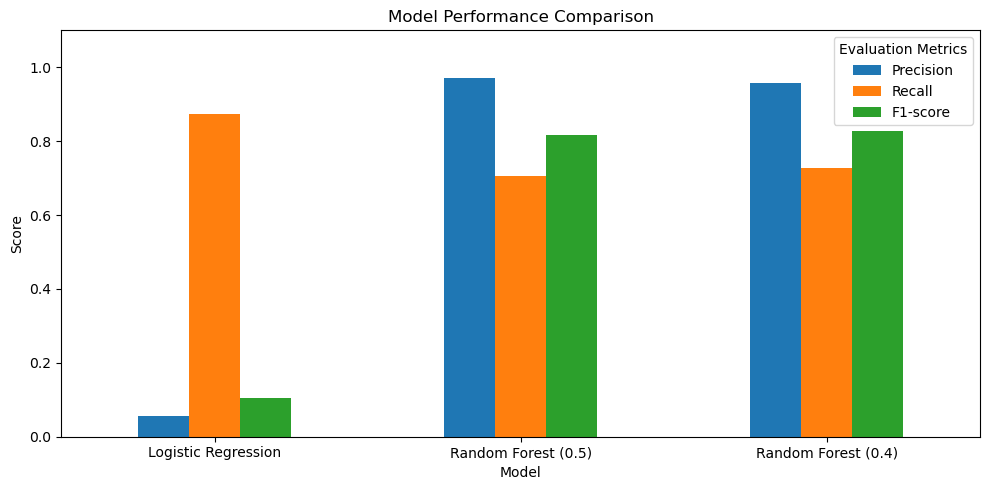

In [81]:
metrics.plot(kind='bar', figsize=(10, 5))

plt.title('Model Performance Comparison')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1.1)
plt.legend(title='Evaluation Metrics')
plt.tight_layout()
plt.show()

## Results and Findings

In this project, I trained two machine learning models, Logistic Regression and Random Forest, to identify fraudulent credit card transactions.

The dataset originally contained 284,807 transactions. During data cleaning, I found and removed 1,081 duplicate records, leaving 283,726 transactions. Out of these, only 473 were fraudulent, showing that the dataset was highly imbalanced.

After training and testing both models, I obtained the following results:

- **Logistic Regression:** The model correctly identified 83 out of 95 fraudulent transactions, giving it a recall of 87.37%. However, its precision was only 5.64%, meaning that many legitimate transactions were wrongly classified as fraudulent.

- **Random Forest (0.5):** This model performed much better in terms of precision, achieving 97.10%. However, its recall was 70.53%, while its F1-score was 81.71%.

- **Random Forest (0.4):** After testing different probability thresholds on a validation set, I selected 0.4. Using this threshold on the original Random Forest model improved its recall to 72.63% and F1-score to 82.63%, although precision reduced slightly to 95.83%.

Based on these results, I selected Random Forest with a 0.4 probability threshold because it achieved the highest F1-score among the three configurations.

## Limitations and Recommendations

Although the Random Forest model produced encouraging results, there are still some areas that need improvement.

### Limitations

1. **Imbalanced dataset:** Fraudulent transactions accounted for only about 0.17% of the dataset. This made it difficult for the models to identify fraud without wrongly classifying legitimate transactions.

2. **Undetected fraud:** Even after adjusting the probability threshold, the selected model still failed to identify 26 out of the 95 fraudulent transactions in the test set.

3. **Limited information about the features:** Most of the features were labelled V1 to V28 because they had already undergone PCA transformation. This made it difficult to understand what each feature represented in the original transaction data.

4. **Number of models tested:** I only trained and compared two machine learning algorithms, so there is still room to explore other approaches.

### Recommendations

To improve the project in the future, I would consider the following:

- Try other classification algorithms, such as XGBoost and Gradient Boosting, to see whether they can produce better results.
- Explore techniques such as SMOTE to address the class imbalance, while ensuring that any resampling is applied only to the training data.
- Use cross-validation to check whether the models perform consistently across different training and validation sets.
- Examine precision-recall curves to better understand how changing the probability threshold affects fraud detection.
- Consider the financial implications of missed fraudulent transactions and false alarms when deciding on the most suitable model.

## Conclusion

The aim of this project was to develop a machine learning model that could identify fraudulent credit card transactions.

I started by exploring and cleaning the dataset, checking for missing values and duplicate records, and examining the distribution of fraudulent and legitimate transactions. I then prepared the data for training and used Logistic Regression and Random Forest to build two classification models.

After evaluating both models, I found that Logistic Regression detected more fraudulent transactions but also wrongly flagged a large number of legitimate transactions.

Random Forest performed better in terms of precision and F1-score. I also tested different probability thresholds and found that reducing the threshold from 0.5 to 0.4 improved the Random Forest model's F1-score from 81.71% to 82.63%.

Based on the results, I selected Random Forest with a 0.4 threshold as the preferred model for this project.

However, the model still missed 26 fraudulent transactions in the test set. This shows that although the results are promising, further improvements and testing would be necessary before using the model in a real-world fraud detection system.

Overall, this project helped me gain practical experience in data preprocessing, handling imbalanced datasets, training classification models, evaluating their performance, and adjusting probability thresholds to improve predictions.

## Saving the trained Random Forest model

### Importing joblib

In [82]:
import joblib

### Saving the trained model and preprocessing components

In [83]:
# Saving the trained Random Forest model
joblib.dump(rf, 'random_forest_model.pkl')

['random_forest_model.pkl']

In [84]:
# Saving the fitted scaler
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [85]:
# Saving the selected probability threshold
joblib.dump(0.4, 'fraud_threshold.pkl')

['fraud_threshold.pkl']

### Verifying the saved model and preprocessing components

In [86]:
# Loading the saved components
loaded_model = joblib.load('random_forest_model.pkl')
loaded_scaler = joblib.load('scaler.pkl')
loaded_threshold = joblib.load('fraud_threshold.pkl')

In [89]:
# Displaying the loaded components
print('Model:', type(loaded_model).__name__)
print('Scaler:', type(loaded_scaler).__name__)
print('Threshold:', loaded_threshold)

Model: RandomForestClassifier
Scaler: StandardScaler
Threshold: 0.4


### Testing the saved Random Forest model

In [90]:
# Scaling the test features using the loaded scaler
X_test_loaded = loaded_scaler.transform(X_test)

In [91]:
# Generating fraud probabilities
loaded_probabilities = loaded_model.predict_proba(X_test_loaded)[:, 1]

In [92]:
# Applying the saved threshold
loaded_predictions = (loaded_probabilities >= loaded_threshold).astype(int)

In [93]:
# Checking whether the predictions match
print(np.array_equal(loaded_predictions, y_pred_rf_optimized))

True
